In [1]:
%load_ext autoreload
%autoreload 2
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [19]:
import sys
sys.path.append("../..")

In [3]:
from PIL import Image
from pathlib import Path

In [8]:
map_folder = Path("../../../../BWTA Results/Raw Map Images/")

In [9]:
mapname = "iccup andromeda 1.0.scx.png"

In [10]:
image = Image.open(map_folder / mapname)

In [45]:
new_size = (128, 128)

In [46]:
image_small = image.resize(new_size, resample=Image.NEAREST)

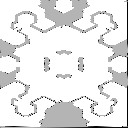

In [47]:
image_small

In [48]:
image_small.size

(128, 128)

In [49]:
image_small_array = np.array(image_small)

In [50]:
from world_rando.room_perception.isovision import *

In [51]:
blank = image_small_array[(10,10)]

In [52]:
blank

array([255, 255, 255, 205], dtype=uint8)

In [53]:
processed_image_array = np.zeros((image_small_array.shape[0], image_small_array.shape[1]))
for i in iter2d(image_small_array):
    #print(image_small_array[i])
    if np.all(image_small_array[i] == blank):
        processed_image_array[i] = 1
    else:
        processed_image_array[i] = -1

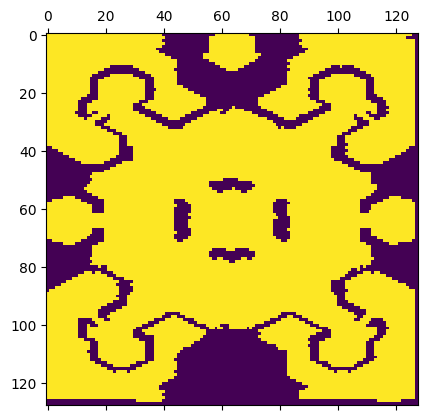

In [54]:
matshow(processed_image_array)

In [55]:
is_air = processed_image_array

In [56]:
from world_rando.room_perception.perceptual_flux import *

In [57]:
surface_probs, infos = compute_surfaces(is_air)

  0%|          | 0/16384 [00:00<?, ?it/s]

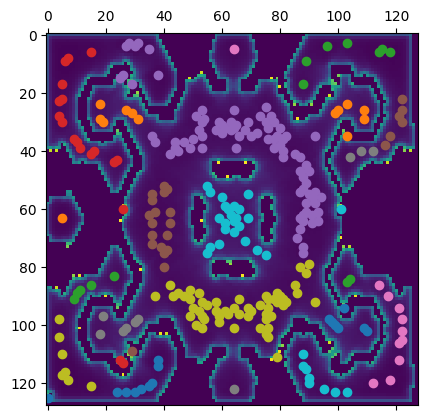

In [61]:
glom = show_clusters(is_air, surface_probs, infos, segs=False, threshold=0.5)